<a href="https://colab.research.google.com/github/MirandaBazalar/Datos-espaciales-mobiles/blob/main/examen_mobiles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import pandas as pd

In [11]:
from google.colab import files

In [12]:
uploaded = files.upload()

Saving some_dataworld.csv to some_dataworld (1).csv


In [13]:
someData=pd.read_csv('some_dataworld (1).csv')

In [14]:
someData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172 entries, 0 to 171
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country       172 non-null    object 
 1   iso2          171 non-null    object 
 2   iso3          172 non-null    object 
 3   region        172 non-null    object 
 4   fragility     172 non-null    float64
 5   co2           172 non-null    int64  
 6   sq_km         172 non-null    int64  
 7   num_airports  172 non-null    int64  
 8   population    172 non-null    int64  
 9   mobiles       172 non-null    int64  
dtypes: float64(1), int64(5), object(4)
memory usage: 13.6+ KB


In [ ]:
from google.colab import files

In [7]:
uploaded = files.upload()

Saving worldMaps.gpkg to worldMaps (1).gpkg


In [16]:
import geopandas as gpd

In [17]:
gpd.list_layers('worldMaps.gpkg')

,name,geometry_type
0,rivers,MultiLineString
1,cities,Point
2,countries,MultiPolygon


In [18]:
countries = gpd.read_file('worldMaps.gpkg', layer='countries')

In [19]:
countries.head()

,COUNTRY,geometry
0,Aruba (Netherlands),"MULTIPOLYGON (((-69.88223 12.41111, -69.94695 ..."
1,Antigua and Barbuda,"MULTIPOLYGON (((-61.73889 17.54055, -61.75195 ..."
2,Afghanistan,"MULTIPOLYGON (((61.27656 35.60725, 61.29638 35..."
3,Algeria,"MULTIPOLYGON (((-5.15213 30.18047, -5.13917 30..."
4,Azerbaijan,"MULTIPOLYGON (((46.54037 38.87559, 46.49554 38..."


In [20]:
someData.head()

,Country,iso2,iso3,region,fragility,co2,sq_km,num_airports,population,mobiles
0,AFGHANISTAN,AF,AFG,SOUTH ASIA,105.0,7893000,652230,68,40121552,23000000
1,ALBANIA,AL,ALB,EUROPE,58.9,3794000,28748,3,3107100,2610000
2,ALGERIA,DZ,DZA,AFRICA,75.4,151633000,2381740,95,47022473,51500000
3,ANGOLA,AO,AGO,AFRICA,87.8,19362000,1246700,107,37202061,25700000
4,ANTIGUA AND BARBUDA,AG,ATG,CENTRAL AMERICA AND THE CARIBBEAN,54.4,729000,443,4,102634,184000


In [21]:
countries.rename(columns={'COUNTRY':'Country'}, inplace=True)

In [22]:
countries['Country']=countries.Country.str.upper()

In [23]:
onlyDF=set(someData.Country) - set(countries.Country)
onlyGDF = set(countries.Country) - set(someData.Country)

onlyDF

{'BAHAMAS (THE)',
 'BOLIVIA (PLURINATIONAL STATE OF)',
 'BRUNEI DARUSSALAM',
 'CABO VERDE',
 'CENTRAL AFRICAN REPUBLIC (THE)',
 'COMOROS (THE)',
 'CONGO (THE DEMOCRATIC REPUBLIC OF THE)',
 'CONGO (THE)',
 "CÔTE D'IVOIRE",
 'DOMINICAN REPUBLIC (THE)',
 'ESWATINI',
 'GAMBIA (THE)',
 'IRAN (ISLAMIC REPUBLIC OF)',
 'KOREA (THE REPUBLIC OF)',
 "LAO PEOPLE'S DEMOCRATIC REPUBLIC (THE)",
 'MICRONESIA (FEDERATED STATES OF)',
 'MOLDOVA (THE REPUBLIC OF)',
 'NETHERLANDS (THE)',
 'NIGER (THE)',
 'NORTH MACEDONIA',
 'NORTHERN MARIANA ISLANDS (THE)',
 'PHILIPPINES (THE)',
 'RUSSIAN FEDERATION (THE)',
 'SAMOA',
 'SUDAN (THE)',
 'TANZANIA, THE UNITED REPUBLIC OF',
 'TIMOR-LESTE',
 'UNITED ARAB EMIRATES (THE)',
 'UNITED KINGDOM OF GREAT BRITAIN AND NORTHERN IRELAND (THE)',
 'UNITED STATES OF AMERICA (THE)'}

In [24]:
onlyGDF

{'AMERICAN SAMOA (US)',
 'AMERICAN VIRGIN ISLANDS (US)',
 'ANDORRA',
 'ANGUILLA (UK)',
 'ANTARCTICA',
 'ARUBA (NETHERLANDS)',
 'BAHAMAS',
 'BAKER ISLAND (US)',
 'BERMUDA (UK)',
 'BOLIVIA',
 'BONAIRE (NETHERLANDS)',
 'BOUVET ISLAND (NORWAY)',
 'BRITISH INDIAN OCEAN TERRITORY (UK)',
 'BRITISH VIRGIN ISLANDS(UK)',
 'BRUNEI',
 'CAPE VERDE',
 'CAYMAN ISLANDS (UK)',
 'CENTRAL AFRICAN REPUBLIC',
 'CHRISTMAS ISLAND (AUSTRALIA)',
 'COCOS (KEELING) ISLANDS (AUSTRALIA)',
 'COMOROS',
 'CONGO',
 'COOK ISLANDS (NEW ZEALAND)',
 'CURACAO (NETHERLANDS)',
 'CZECH REPUBLIC',
 'DEMOCRATIC REPUBLIC OF THE CONGO',
 'DOMINICA',
 'DOMINICAN REPUBLIC',
 'EAST TIMOR',
 'ERITREA',
 'FALKLAND ISLANDS (UK)',
 'FAROE ISLANDS (DENMARK)',
 'FEDERATED STATES OF MICRONESIA',
 'FRENCH GUIANA (FRANCE)',
 'FRENCH POLYNESIA (FRANCE)',
 'FRENCH SOUTHERN & ANTARCTIC LANDS (FRANCE)',
 'GAMBIA',
 'GIBRALTAR (UK)',
 'GLORIOSO ISLANDS (FRANCE)',
 'GREENLAND (DENMARK)',
 'GUADELOUPE (FRANCE)',
 'GUAM (US)',
 'GUERNSEY (UK)',
 'HE

In [25]:
someData.region.value_counts()

,count
region,
AFRICA,52
EUROPE,37
MIDDLE EAST,16
CENTRAL AMERICA AND THE CARIBBEAN,16
EAST AND SOUTHEAST ASIA,15
SOUTH AMERICA,12
SOUTH ASIA,8
AUSTRALIA AND OCEANIA,7
CENTRAL ASIA,6


In [26]:
americas = someData[
    someData['region'].isin([
        'NORTH AMERICA',
        'SOUTH AMERICA',
        'CENTRAL AMERICA AND THE CARIBBEAN'
    ])
]

americas [['Country','region']]

,Country,region
4,ANTIGUA AND BARBUDA,CENTRAL AMERICA AND THE CARIBBEAN
5,ARGENTINA,SOUTH AMERICA
10,BAHAMAS (THE),CENTRAL AMERICA AND THE CARIBBEAN
13,BARBADOS,CENTRAL AMERICA AND THE CARIBBEAN
16,BELIZE,CENTRAL AMERICA AND THE CARIBBEAN
19,BOLIVIA (PLURINATIONAL STATE OF),SOUTH AMERICA
22,BRAZIL,SOUTH AMERICA
30,CANADA,NORTH AMERICA
33,CHILE,SOUTH AMERICA
35,COLOMBIA,SOUTH AMERICA


In [27]:
americas_gdf = countries[countries['Country'].isin(americas['Country'])]
americas_gdf[['Country']]

,Country
1,ANTIGUA AND BARBUDA
10,ARGENTINA
16,BARBADOS
22,BELIZE
29,BRAZIL
35,CANADA
42,CHILE
47,COLOMBIA
49,COSTA RICA
51,CUBA


In [75]:
someData['Country']=someData['Country'].replace({
    'BAHAMAS (THE)': 'BAHAMAS',
    'BOLIVIA (PLURINATIONAL STATE OF)': 'BOLIVIA',
    'DOMINICAN REPUBLIC (THE)':'DOMINICAN REPUBLIC',
    'UNITED STATES OF AMERICA (THE)': 'UNITED STATES'
})

In [76]:
theMapAndData=countries.merge(someData,on= 'Country')

theMapAndData.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 146 entries, 0 to 145
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   Country       146 non-null    object  
 1   geometry      146 non-null    geometry
 2   iso2          145 non-null    object  
 3   iso3          146 non-null    object  
 4   region        146 non-null    object  
 5   fragility     146 non-null    float64 
 6   co2           146 non-null    int64   
 7   sq_km         146 non-null    int64   
 8   num_airports  146 non-null    int64   
 9   population    146 non-null    int64   
 10  mobiles       146 non-null    int64   
dtypes: float64(1), geometry(1), int64(5), object(4)
memory usage: 12.7+ KB


In [77]:
americasMap = theMapAndData[
    theMapAndData['region'].isin([
        'NORTH AMERICA',
        'SOUTH AMERICA',
        'CENTRAL AMERICA AND THE CARIBBEAN'
    ])
]

In [78]:
len(americasMap)

31

In [31]:
americasMap.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [79]:
americasMap_8857 = americasMap.to_crs(epsg=8857)

In [33]:
americasMap_8857.crs

<Projected CRS: EPSG:8857>
Name: WGS 84 / Equal Earth Greenwich
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Coordinate Operation:
- name: Equal Earth Greenwich
- method: Equal Earth
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [89]:
americasMap_8857[['Country','mobiles']].sort_values('mobiles',ascending=False)

,Country,mobiles
134,UNITED STATES,386000000
22,BRAZIL,213000000
93,MEXICO,140000000
33,COLOMBIA,87400000
7,ARGENTINA,62700000
103,PERU,41300000
26,CANADA,36500000
31,CHILE,26700000
56,GUATEMALA,20600000
138,VENEZUELA,18800000


In [88]:
justDots = americasMap_8857.copy()

In [86]:
dot_value = 1000000

In [90]:
justDots['num_dots']=(justDots['mobiles'] / dot_value).astype(int)

In [91]:
justDots = justDots.sample_points(size=justDots['num_dots']).explode(index_parts=True)

In [92]:
justDots.reset_index(drop=True, inplace=True)

In [93]:
americas_dots = gpd.GeoDataFrame(geometry=justDots)

<Axes: >

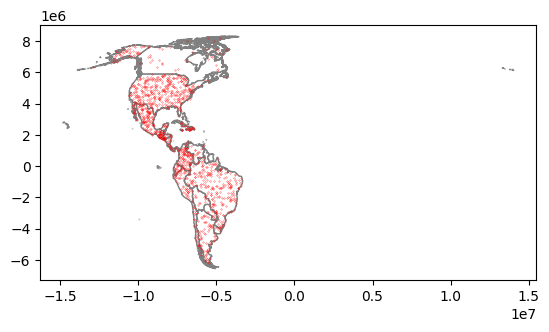

In [94]:
base = americasMap_8857.plot(
    facecolor="white",
    edgecolor="grey"
)

americas_dots.plot(
    markersize=0.05,
    color="red",
    ax=base
)

In [95]:
americasMap_8857 = americasMap.to_crs(8857)
americas_dots_8857 = americas_dots.to_crs(8857)

In [96]:
americas_8857_symbols = americasMap_8857.copy()
americas_8857_symbols['geometry'] = americas_8857_symbols['geometry'].centroid

In [97]:
americas_8857_symbols['size'] = americas_8857_symbols['mobiles'].apply (lambda x: x**0.5/100)

<Axes: >

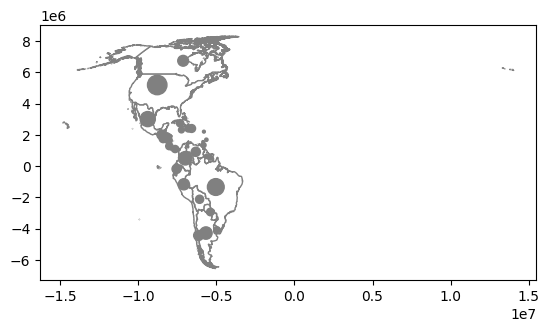

In [98]:
base = americasMap_8857.plot(
    facecolor="white",
    edgecolor= "grey"
)

americas_8857_symbols.plot(
    ax=base,
    markersize=americas_8857_symbols['size'],
    color= 'grey'
)

In [99]:
americasMap_8857['mobile_rate']= (
    americasMap_8857['mobiles'] / americasMap_8857['population']
)

In [101]:
import mapclassify
import numpy as np

np.random.seed(12345)

K= 5
theVar = americasMap_8857['mobile_rate']

fj5 = mapclassify.FisherJenks(theVar, k=K)

In [102]:
ei5 = mapclassify.EqualInterval (theVar, k=K)
msd = mapclassify.StdMean(theVar)
q5 = mapclassify.Quantiles(theVar, k=K)
mb5 = mapclassify.MaximumBreaks(theVar, k=K)
ht = mapclassify.HeadTailBreaks(theVar)
fj5  = mapclassify.FisherJenks(theVar, k=K)
jc5 = mapclassify.JenksCaspall(theVar, k=K)
mp5 = mapclassify.MaxP(theVar, k=K)


In [103]:
class5 = ei5, msd,q5,mb5,ht,fj5,jc5,mp5
fits = np.array([c.adcm for c in class5])
adcms = pd.DataFrame (fits)
adcms['classifier'] = [c.name for c in class5]
adcms.columns = ['ADCM', 'Classifier']

<Axes: ylabel='Classifier'>

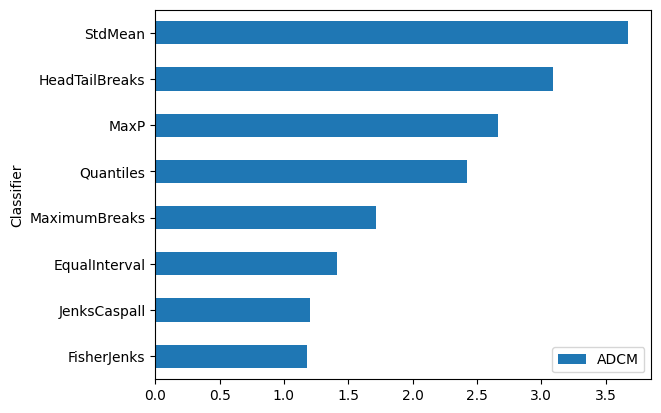

In [104]:
adcms.sort_values('ADCM').plot.barh(x='Classifier')

In [106]:
americasMap_8857['mobile_rate_FJ5']= fj5.yb

In [107]:
newLabelsForLevels = {
    0:"0_VeryLow",
    1:"1_Low",
    2:"2_Middle",
    3:"3_High",
    4:"4_VeryHigh"
}

americasMap_8857['mobile_rate_FJ5_cat'] = (
    americasMap_8857['mobile_rate_FJ5'].replace(newLabelsForLevels)
)

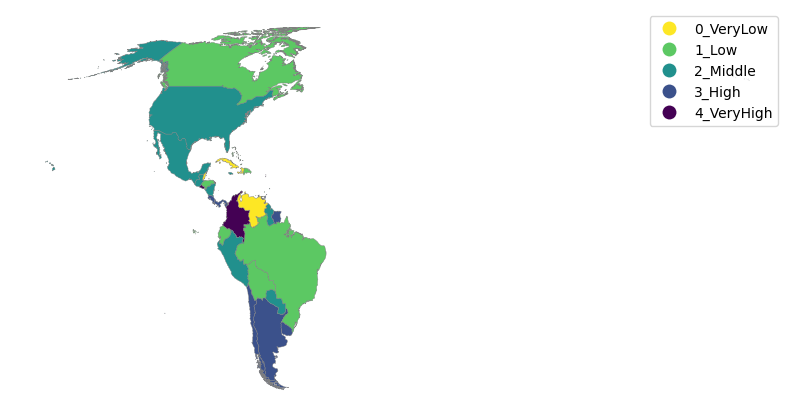

In [109]:
import matplotlib.pyplot as plt

f, ax = plt.subplots(1, figsize= (10, 10))

americasMap_8857.plot(
    column='mobile_rate_FJ5_cat',
    cmap='viridis_r',
    categorical=True,
    edgecolor='grey',
    linewidth=0.3,
    legend=True,
    ax=ax
)

ax.set_axis_off()